# **Customer Segmentation Analysis Using K-Means Clustering for Designing Personalized Retail Marketing Strategies.**

Proyek ini berfokus pada segmentasi pelanggan menggunakan analisis RFM (Recency, Frequency, Monetary) dan metode K-Means Clustering untuk mengidentifikasi pola pembelian serta mengelompokkan pelanggan berdasarkan perilaku transaksi mereka. Analisis ini juga mencakup identifikasi risiko churn, estimasi Customer Lifetime Value (CLV), dan penyusunan rekomendasi strategi pemasaran yang sesuai dengan karakteristik setiap segmen pelanggan.

## Dataset

Dataset yang digunakan berasal dari Kaggle, yaitu [E-Commerce Dataset for SQL Analysis](https://www.kaggle.com/datasets/nabihazahid/ecommerce-dataset-for-sql-analysis). Dataset ini berisi data transaksi e-commerce yang digunakan untuk mengeksplorasi perilaku pembelian pelanggan dan pola penjualan. Data tersebut menjadi dasar dalam proses pengolahan data, analisis RFM, segmentasi pelanggan, serta penyusunan rekomendasi strategi pemasaran.

##1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
from sklearn.metrics import silhouette_score
from scipy.stats import mode
from sklearn.metrics.pairwise import cosine_similarity

##2. Preprocessing Data

In [ ]:
df = pd.read_csv('ecommerce_dataset_10000.csv')

In [ ]:
df

,customer_id,first_name,last_name,gender,age_group,signup_date,country,product_id,product_name,category,quantity,unit_price,order_id,order_date,order_status,payment_method,rating,review_text,review_id,review_date
0,CUST2353,Erica,Oliver,Female,Teenagers,2022-06-29,Canada,PROD108,Fitbit Versa 3,Electronics,3,229,ORD10000,2023-07-13,Pending,Credit Card,2,good,REV20000,2025-06-06
1,CUST4463,Christopher,White,Male,Adults,2023-08-24,China,PROD103,Levi's Jeans,Apparel,4,59,ORD10001,2024-08-12,Pending,PayPal,2,average,REV20001,2023-08-05
2,CUST4512,Spencer,Foster,Male,Senior,2023-07-18,Germany,PROD111,Lego Star Wars Set,Toys,2,59,ORD10002,2024-08-04,Delivered,Cash on Delivery,5,good,REV20002,2023-01-03
3,CUST5711,Jessica,Harris,Male,Teenagers,2025-08-22,France,PROD107,Dyson Vacuum,Home & Kitchen,4,399,ORD10003,2025-05-23,Delivered,Cash on Delivery,2,very good,REV20003,2023-03-14
4,CUST1296,Amy,Johnson,Female,Teenagers,2021-03-23,Brazil,PROD105,Adidas Running Shoes,Apparel,1,110,ORD10004,2023-07-02,Returned,Cash on Delivery,1,very good,REV20004,2023-10-18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,CUST2529,Lisa,Coleman,Male,Senior,2023-01-06,UK,PROD109,Kindle Paperwhite,Books,5,129,ORD19995,2023-06-07,Delivered,PayPal,4,very good,REV29995,2024-07-30
9996,CUST4602,Stacy,Brown,Other,Teenagers,2023-08-30,Canada,PROD109,Kindle Paperwhite,Books,5,129,ORD19996,2025-08-05,Returned,PayPal,1,bad,REV29996,2024-09-13
9997,CUST1448,Sheila,Roberts,Other,Adults,2024-05-18,USA,PROD107,Dyson Vacuum,Home & Kitchen,5,399,ORD19997,2023-12-23,Returned,Cash on Delivery,3,average,REV29997,2023-09-13
9998,CUST1343,Paul,Lam,Male,Teenagers,2024-07-14,Canada,PROD107,Dyson Vacuum,Home & Kitchen,3,399,ORD19998,2022-08-30,Cancelled,Credit Card,2,very good,REV29998,2025-07-07


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customer_id     10000 non-null  object
 1   first_name      10000 non-null  object
 2   last_name       10000 non-null  object
 3   gender          10000 non-null  object
 4   age_group       10000 non-null  object
 5   signup_date     10000 non-null  object
 6   country         10000 non-null  object
 7   product_id      10000 non-null  object
 8   product_name    10000 non-null  object
 9   category        10000 non-null  object
 10  quantity        10000 non-null  int64 
 11  unit_price      10000 non-null  int64 
 12  order_id        10000 non-null  object
 13  order_date      10000 non-null  object
 14  order_status    10000 non-null  object
 15  payment_method  10000 non-null  object
 16  rating          10000 non-null  int64 
 17  review_text     10000 non-null  object
 18  review_

In [ ]:
df.describe()

,quantity,unit_price,rating
count,10000.000000,10000.000000,10000.000000
mean,3.000800,246.647200,2.993100
std,1.416474,282.605391,1.410621
min,1.000000,25.000000,1.000000
25%,2.000000,80.000000,2.000000
50%,3.000000,129.000000,3.000000
75%,4.000000,229.000000,4.000000
max,5.000000,999.000000,5.000000


In [ ]:
df.isnull().sum()

,0
customer_id,0
first_name,0
last_name,0
gender,0
age_group,0
signup_date,0
country,0
product_id,0
product_name,0
category,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
total_customers = df['customer_id'].nunique()
total_customers

4327

In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'])

In [ ]:
current_date = df['order_date'].max()

##3. RFM (Recency, Frequency, Monetary)

In [ ]:
df['TotalAmount'] = df['quantity'] * df['unit_price']

In [ ]:
df_rfm = df.groupby('customer_id').agg({
    'order_date': lambda x: (current_date - x.max()).days,
    'order_id': 'nunique',
    'TotalAmount': 'sum'
}).reset_index()

df_rfm.columns = ['customer_id', 'Recency', 'Frequency', 'Monetary']

df_rfm

,customer_id,Recency,Frequency,Monetary
0,CUST1000,237,5,6336
1,CUST1001,138,2,690
2,CUST1002,1019,1,999
3,CUST1003,603,2,444
4,CUST1004,222,1,796
...,...,...,...,...
4322,CUST5993,694,1,796
4323,CUST5994,583,3,2342
4324,CUST5997,35,1,798
4325,CUST5998,83,4,1653


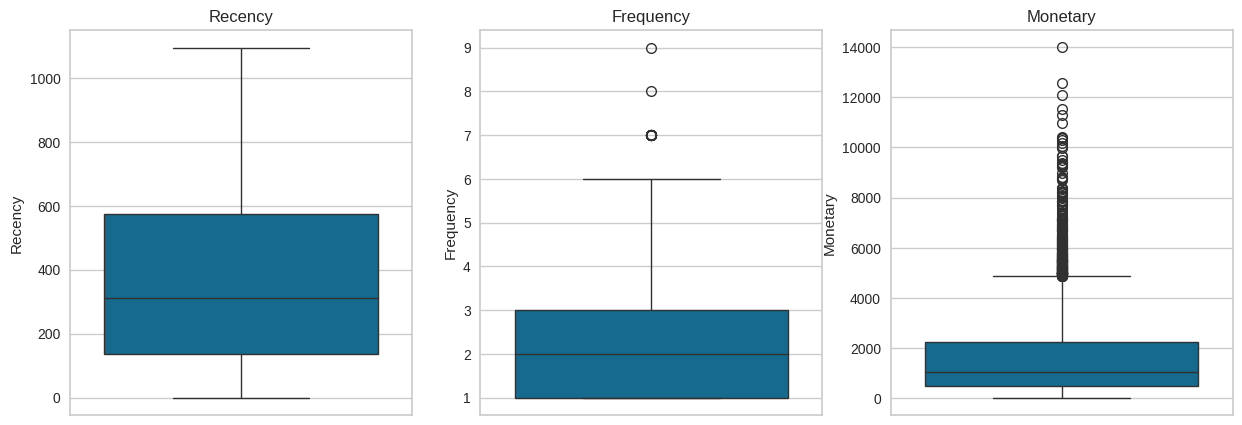

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.boxplot(y=df_rfm['Recency'], ax=axes[0])
sns.boxplot(y=df_rfm['Frequency'], ax=axes[1])
sns.boxplot(y=df_rfm['Monetary'], ax=axes[2])
axes[0].set_title('Recency')
axes[1].set_title('Frequency')
axes[2].set_title('Monetary')
plt.show()

**1. Recency**
- Mayoritas pelanggan memiliki nilai Recency antara sekitar 100–600 hari sejak transaksi terakhir.
- Median ada di sekitar 300 hari.
- Terlihat ada beberapa outlier di bagian atas, yaitu pelanggan yang sangat lama tidak bertransaksi, bahkan hingga mendekati 1100 hari.

- Pelanggan yang menjadi outlier Recency adalah mereka yang sangat tidak aktif.
- Mereka bisa dianggap sebagai pelanggan dormant (tidak kembali membeli dalam waktu sangat lama).

**2. Frequency**
- Sebagian besar pelanggan hanya melakukan 1–3 kali transaksi unik.
- Median berada pada sekitar 2 transaksi.
- Outlier terlihat jelas, yaitu pelanggan dengan Frequency 7, 8, hingga 9 kali.

- Outlier ini adalah pelanggan yang sangat loyal atau sangat aktif.
- Walaupun sedikit jumlahnya, mereka biasanya termasuk top customers.
- Ini adalah pola alami dalam bisnis, sebagian besar pelanggan membeli sedikit, hanya sebagian kecil yang membeli berulang kali.

**3. Monetary**
- Mayoritas pelanggan menghabiskan antara Rp 200 – Rp 2.000.
- Median Monetary berada sekitar Rp 1.000-an.
- Tetapi ada banyak sekali outlier.
Ada pelanggan yang menghabiskan Rp 5.000 – Rp 14.000. Outlier sangat padat di bagian atas.

- Outlier pada Monetary menunjukkan pelanggan dengan nilai belanja sangat tinggi (big spenders).
- Ini juga umum: biasanya hanya sebagian kecil pelanggan yang menghasilkan sebagian besar total revenue.

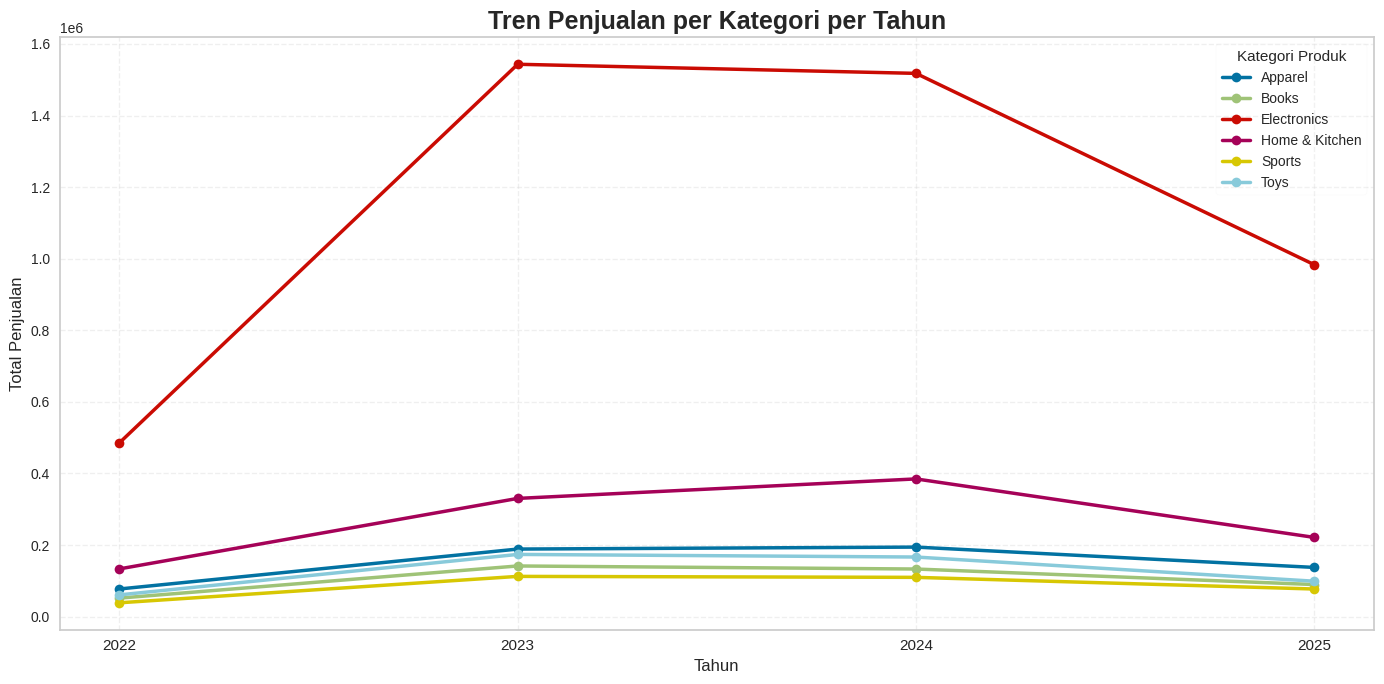

In [ ]:
df['monetary'] = df['quantity'] * df['unit_price']
df['year'] = df['order_date'].dt.year
grouped = df.groupby(['year', 'category'])['monetary'].sum().reset_index()
pivot = grouped.pivot(index='year', columns='category', values='monetary')

plt.figure(figsize=(14, 7))
colors = plt.cm.tab10.colors
for i, column in enumerate(pivot.columns):
    plt.plot(
        pivot.index,
        pivot[column],
        label=column,
        linewidth=2.5,
        marker='o',
        markersize=7
    )

plt.title("Tren Penjualan per Kategori per Tahun", fontsize=18, weight='bold')
plt.xlabel("Tahun", fontsize=12)
plt.ylabel("Total Penjualan", fontsize=12)

plt.grid(True, linestyle='--', alpha=0.3)

plt.legend(
    title="Kategori Produk",
    fontsize=10,
    title_fontsize=11,
    frameon=True,
    shadow=False,
    fancybox=True,
    framealpha=0.15
)

plt.xticks(pivot.index, fontsize=11)
plt.tight_layout()
plt.show()

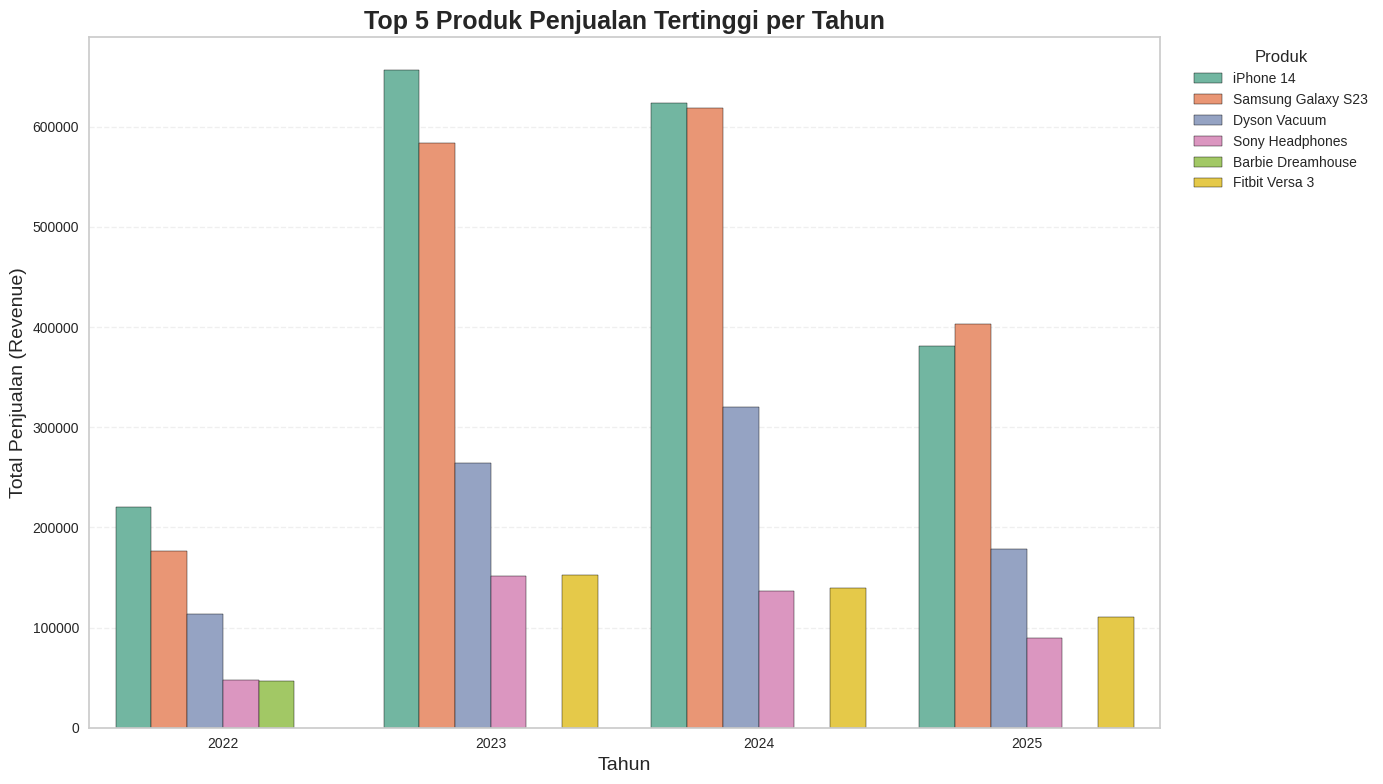

In [ ]:
df['revenue'] = df['quantity'] * df['unit_price']

yearly_sales = (df.groupby(['year','product_name'])['revenue']
                  .sum()
                  .reset_index())

top5 = (yearly_sales.sort_values(['year','revenue'], ascending=[True, False])
                 .groupby('year')
                 .head(5))

plt.figure(figsize=(14, 8))
sns.barplot(
    data=top5,
    x='year',
    y='revenue',
    hue='product_name',
    palette='Set2',
    edgecolor='black'
)

plt.title("Top 5 Produk Penjualan Tertinggi per Tahun", fontsize=18, weight='bold')
plt.xlabel("Tahun", fontsize=14)
plt.ylabel("Total Penjualan (Revenue)", fontsize=14)
plt.legend(title="Produk", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

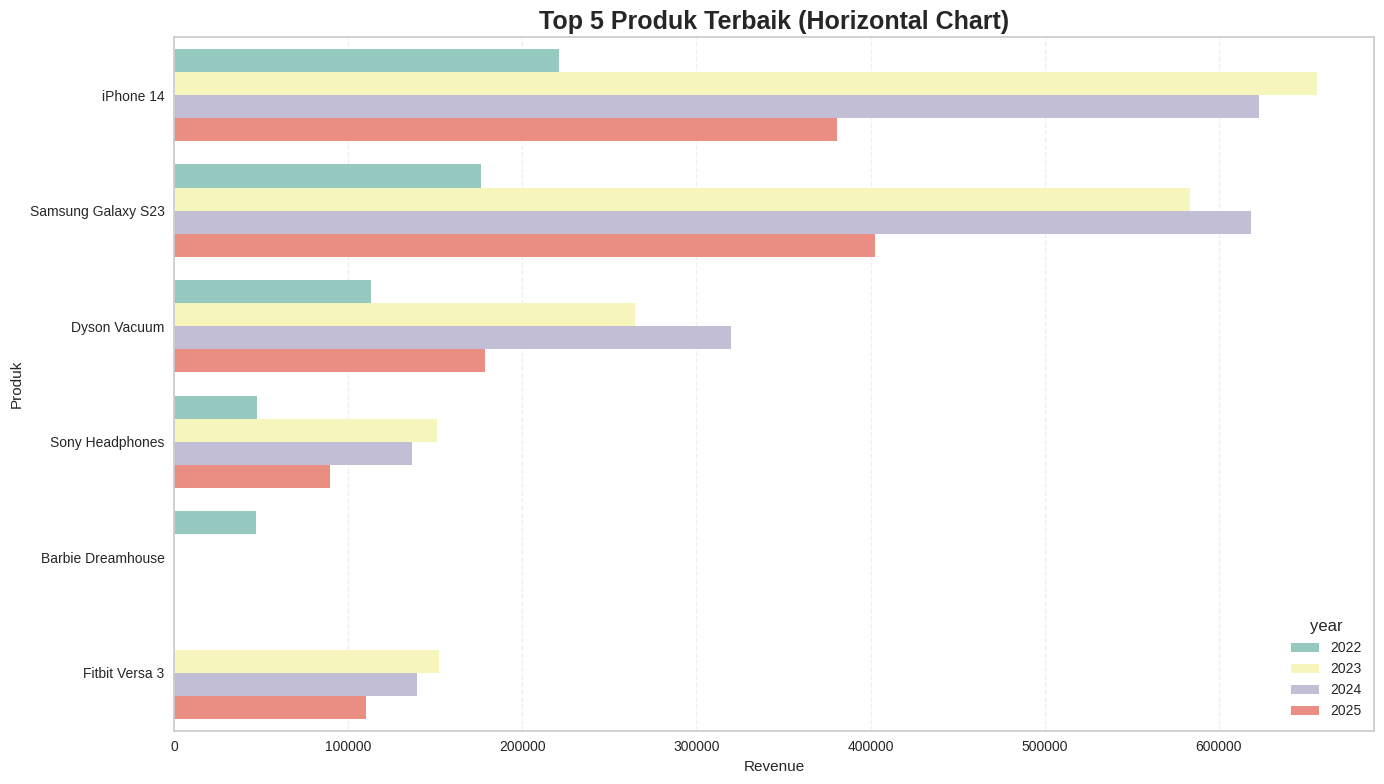

In [ ]:
plt.figure(figsize=(14, 8))

sns.barplot(
    data=top5,
    y='product_name',
    x='revenue',
    hue='year',
    palette='Set3'
)

plt.title("Top 5 Produk Terbaik (Horizontal Chart)", fontsize=18, weight='bold')
plt.xlabel("Revenue")
plt.ylabel("Produk")
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(df_rfm[['Recency','Frequency','Monetary']])

##4. Elbow Method

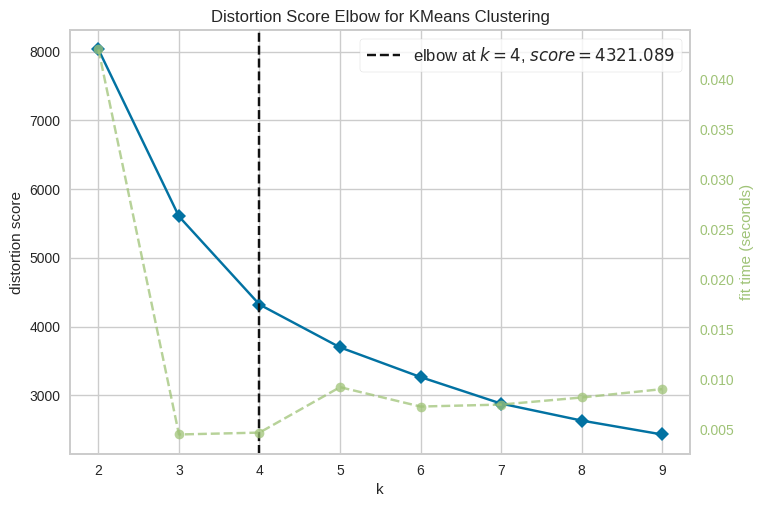

Optimal K: 4


In [ ]:
kmeans = KMeans()
visualizer = KElbowVisualizer(kmeans, k=(2, 10))

visualizer.fit(rfm_scaled)
visualizer.show()

optimal_k = visualizer.elbow_value_
print("Optimal K:", optimal_k)


Memilih menggunakan 4 cluster karena:
- Nilai silhoutte sedikit lebih tinggi jika dibandingkan 3 cluster.
- Cluster juga akan lebih spesifik dan actionable untuk bisnis artinya segmentasi pelanggan yang dihasilkan lebih mudah digunakan untuk mengambil tindakan nyata (actions). Serta bisa membuat strategi bisnis yang lebih spesifik, tepat sasaran, dan efektif, dibandingkan cluster yang terlalu sedikit.
- Outlier Monetary membuat struktur pelanggan lebih bervariasi, dan 4 cluster menangkap variasi itu.

##5. Clustering KMeans

In [ ]:
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
df_rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

In [ ]:
joblib.dump(kmeans, "kmeans_rfm_model.pkl")

['kmeans_rfm_model.pkl']

In [ ]:
score = silhouette_score(rfm_scaled, df_rfm['Cluster'])
print("Silhouette Score:", score)

Silhouette Score: 0.3589681132773589


##6. Interpretasi Cluster

In [ ]:
df_rfm.groupby('Cluster')[['Recency','Frequency','Monetary']].agg(['mean','min','max','count'])

Recency                  Frequency                   Monetary  \
               mean  min   max count      mean min max count         mean   
Cluster                                                                     
0        216.545852    0   696  1145  3.632314   3   7  1145  1730.659389   
1        774.368329  498  1095  1143  1.418198   1   3  1143   894.573928   
2        240.537179    0   517  1439  1.593468   1   2  1439   859.829743   
3        269.800000    0   910   600  3.211667   1   9   600  5348.941667   

                            
          min    max count  
Cluster                     
0         204   4063  1145  
1          25   5020  1143  
2          25   3996  1439  
3        3343  13985   600

***INTERPRETASI CLUSTER***

**1. Cluster 0 (MID LOYAL): Pelanggan Aktif & Konsisten Belanja Sedang**
- Recency rendah (rata-rata 216 hari → berarti masih cukup dekat/aktif)
- Frequency tinggi (rata-rata 3–7x transaksi unik)
- Monetary sedang (rata-rata Rp1,7 juta)
- Count 1145 pelanggan.
- Cluster ini adalah pelanggan yang cukup aktif, melakukan transaksi beberapa kali dalam setahun, dan nilai belanjanya stabil tapi tidak terlalu besar. Mereka bukan VIP, tetapi pelanggan loyal kelas menengah.

**2. Cluster 1 (DORMANT): Pelanggan Tidak Aktif & Belanja Rendah (Dormant / Churn Risk)**
- Recency sangat tinggi (rata-rata 774 hari → hampir 2 tahun tidak transaksi)
- Frequency sangat rendah (1–3 transaksi saja)
- Monetary rendah (rata-rata Rp894 ribu)
- Count 1143 pelanggan.
- Cluster ini adalah pelanggan yang sudah sangat lama tidak berbelanja. Mereka hanya belanja sedikit dan jarang sejak awal. Ini kelompok yang berpotensi churn atau sudah tidak kembali lagi.

**3. Cluster 2 (NEW/LOW FREQ): Pelanggan Baru / Cukup Aktif tapi Frekuensi Rendah**
- Recency cukup rendah (240 hari → masih lumayan recent)
- Frequency sangat rendah (hanya 1–2 transaksi)
- Monetary rendah-menengah (Rp859 ribu)
- Count 1439 pelanggan.
- Cluster ini adalah pelanggan yang masih cukup baru atau kadang membeli, tapi belum loyal. Mereka datang, membeli sedikit, dan belum kembali lagi.

**4. Cluster 3 (VIP): Pelanggan VIP / High Value & High Monetary**
- Recency cukup rendah (269 hari → masih aktif)
- Frequency tinggi (1–9, rata-rata 3 transaksi)
- Monetary sangat tinggi (rata-rata Rp5,3 juta)
- Count 600 pelanggan.
- Ini adalah kelompok paling berharga dengan belanja tinggi, masih aktif, dan sering membeli. Bahkan ada yang belanja Rp13 juta (max = 13.985). Cluster ini adalah VIP/High Value yang berkontribusi besar pada revenue.

**Kesimpulan:**

- Cluster 3 = VIP → paling penting dijaga
- Cluster 0 = pelanggan aktif yang bisa “naik kelas” jadi VIP
- Cluster 2 = pelanggan baru / semi aktif yang perlu dibina
- Cluster 1 = dormant → butuh strategi winback

***Strategi***

**1. Cluster 3 VIP**

Strategi: loyalty program, early access, layanan premium — sangat tepat.

Kenapa efektif?
VIP punya CLV tinggi; retensi mereka memberi dampak besar pada revenue. Mereka sensitif ke eksklusivitas & pengalaman (bukan hanya diskon).

Taktik konkret & implementasi:
- Loyalty tier: Gold/Platinum dengan benefits (free shipping, faster support, birthday gift).

- Early access: 24–48 jam akses duluan ke koleksi/flash sale.

- Personal account manager / priority CS: nomor hotline atau chat prioritas untuk VIP.

- Exclusive events: webinar, preview produk, undangan offline.

- Cross-sell premium: bundling produk high-ticket dengan diskon kecil.

Contoh pesan:
“Sebagai VIP Gold, dapat akses pre-sale 24 jam — lihat koleksi eksklusif sekarang.”

“Terima kasih sudah menjadi VIP — kami siapkan voucher RpX untuk pembelian berikutnya.”

Metrik pantau:
- Retention rate VIP (30/60/90 hari)

- Avg order value (AOV) VIP

- Churn rate VIP (customer lost)

- Revenue per VIP

Budget & frekuensi:
- Insentif nilai tinggi tapi untuk populasi kecil → ROI tinggi.

- Komunikasi: 1–2x per minggu untuk promosi eksklusif + personal outreach 1x/bulan.

A/B test ide:
- Early access 24 vs 48 jam → pengaruh konversi

- Voucher fixed amount vs free shipping → AOV perubahan

Jebakan:
Jangan “menghargai” VIP dengan diskon besar biasa (merusak margin). Fokus pada pengalaman & eksklusifitas.


**2. Cluster 0 MID LOYAL**

Strategi: upselling, bundling, reward untuk tambah transaksi — tepat dan scalable.

Kenapa efektif?
Mereka sudah loyal; sedikit dorongan bisa menaikkan AOV dan frequency.

Taktik konkret & implementasi:

- Product recommendations: rekomendasi upsell berdasarkan riwayat pembelian.

- Bundling: “Beli 2 dapat diskon 10%” untuk produk pelengkap.

- Points / micro-rewards: kumpulkan poin tiap transaksi → redeem barang kecil.

- Trigger email: 7–14 hari setelah pembelian untuk produk pelengkap.

Contoh pesan:

“Tambah RpX untuk mendapatkan gratis ongkir” (upsell)

“Paket hemat untuk pelanggan setia — hemat 15% jika beli bundle ini.”

Metrik pantau:

- AOV perubahan pasca kampanye

- Frequency (avg transactions per 90 hari)

- Conversion rate halaman rekomendasi

- Redemption rate reward

Budget & frekuensi:

- Insentif moderate; kampanye berkala (dua mingguan atau bulanan).

- Otomasi email + rekomendasi di web/app.

A/B test ide:

- Bundle A (produk A+B) vs Bundle B (A+C) → mana yang lift AOV lebih besar

- Micro-reward (diskon kecil) vs free shipping kecil → mana mendorong repeat buy

Jebakan:

Jangan spam penawaran; mereka aktif tapi bisa jenuh. Fokus relevansi.

**3. Cluster 2 New/Low Freq**

Strategi: edukasi produk, reminder, diskon pembelian ke-2 — sangat tepat untuk “mengonversi” mereka jadi pelanggan reguler.


Kenapa efektif?
Mereka punya potensi: recency masih lumayan baik → waktu respons bagus. Kebutuhan: rasa percaya & alasan beli lagi.

Taktik konkret & implementasi:

- Onboarding sequence (email 1–3): welcome, cara pakai produk, testimoni.

- Follow-up pembelian: email minggu ke-1 minggu ke-3 untuk review + rekomendasi.

- Diskon “second purchase”: mis. 10–15% untuk pembelian kedua dalam 30 hari.

- Educational content: tips penggunaan, video singkat, FAQ produk.

- Reminder/abandoned cart: push notification jika ada yang tertunda.

Contoh pesan:

“Terima kasih! Dapatkan 15% untuk pembelian kedua dalam 14 hari.”

“Cara merawat produk X agar awet — lihat tip singkat.”

Metrik pantau:

- Conversion rate second purchase

- Time to second purchase (median days)

- Repeat purchase rate (30/90 hari)

- Email open & CTR untuk onboarding

Budget & frekuensi:

- Diskon awal kecil–sedang, untuk banyak orang → per hitungan ROI.

- Otomasi intensif di 0–30 hari setelah first purchase.

A/B test ide:

- 10% vs 15% second-purchase coupon

- Reminder timing: 7 hari vs 14 hari → pembelian berikutnya

Jebakan:

Diskon terlalu besar di awal dapat menurunkan perceived value. Lebih baik kombinasikan edukasi + diskon kecil.

**4. Cluster 1 Dormant**

Strategi: winback promo, “we’ve missed you” email, voucher khusus, tetapi butuh penyesuaian eksekusi supaya cost-effective.

Kenapa efektif?
Mereka sudah lama menghilang; kebutuhan: alasan kuat untuk kembali (insentif) + relevansi.

Taktik konkret & implementasi:

- Segmentasi lebih lanjut sebelum kirim: bedakan dormant lama (>18 bulan) vs borderline (6–12 bulan).

- Winback sequence (3–5 tahap):

- Email “We miss you” dengan produk rekomendasi.

- Reminder dengan social proof & review.

- Penawaran voucher limited-time (mis. 20% untuk first order kembali).

- Ultimatum/last-chance + survey “kenapa tidak kembali?”

- Retargeting ads khusus dengan produk yang pernah dilihat/beli.

- Survey kecil + insentif (mis. voucher RpX untuk isi survey) — bantu tahu alasan churn.

Contoh pesan:

“Kami kangen! Dapatkan 20% untuk pembelian pertama kembali — berlaku 7 hari.”

“Apa yang membuat Anda berhenti? Isi 1 menit survey, dapat voucher.”

Metrik pantau:

- Reactivation rate (pembelian setelah kampanye)

- Cost per reacquisition (CPA)

- Revenue uplift dari campaign

- Unsubscribe rate (waspada: dormants bisa juga unfollow)

Budget & frekuensi:

- Gunakan voucher yang lebih agresif untuk dormant yang historically high AOV; untuk low-value dormant, gunakan voucher kecil atau survey.

- Jangan kirim terlalu sering (risiko unsub). Sequence di tiap segmen 3–5 pesan dalam 2–4 minggu.

A/B test ide:

- Voucher value 10% vs 20% → CPA dan reactivation rate

- Konten “we miss you” emosional vs faktual → open & CTR

Jebakan:

Kirim voucher besar ke segmen yang tak bernilai hanya buang biaya. Selalu timbang nilai pelanggan historis (LTV) sebelum memberi insentif besar.

##7. Visualisasi

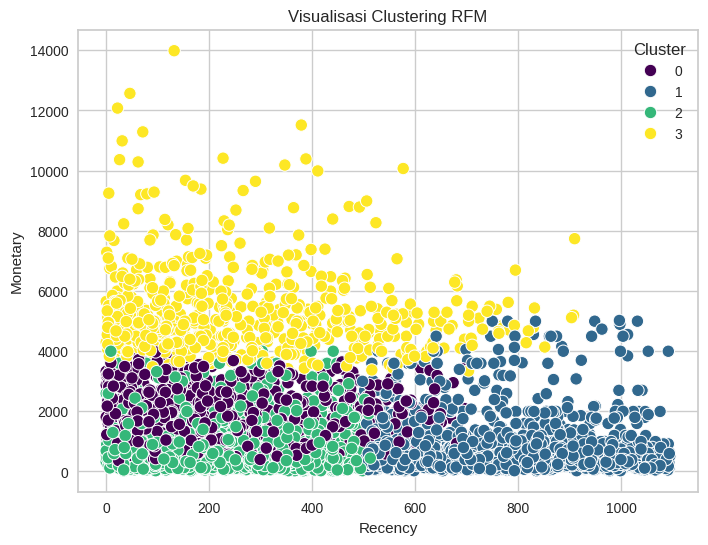

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=80
)

plt.title("Visualisasi Clustering RFM")
plt.xlabel("Recency")
plt.ylabel("Monetary")
plt.legend(title="Cluster")
plt.show()

/tmp/ipykernel_4474/142551651.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


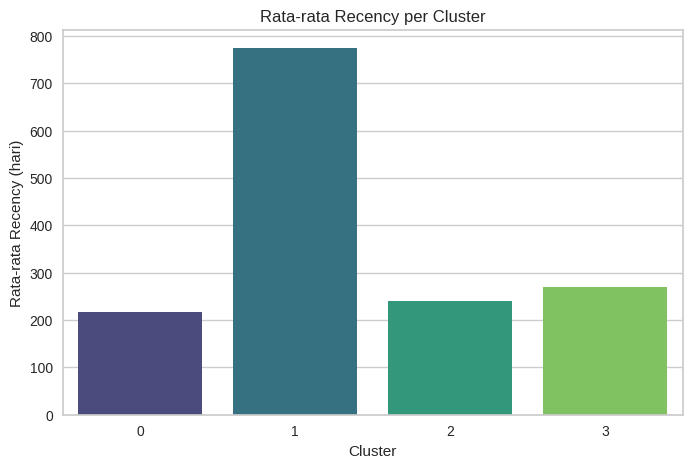

In [ ]:
plt.figure(figsize=(8,5))
recency_mean = df_rfm.groupby('Cluster')['Recency'].mean()

sns.barplot(
    x=recency_mean.index,
    y=recency_mean.values,
    palette='viridis'
)

plt.title("Rata-rata Recency per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Rata-rata Recency (hari)")
plt.show()


/tmp/ipykernel_4474/1782988369.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


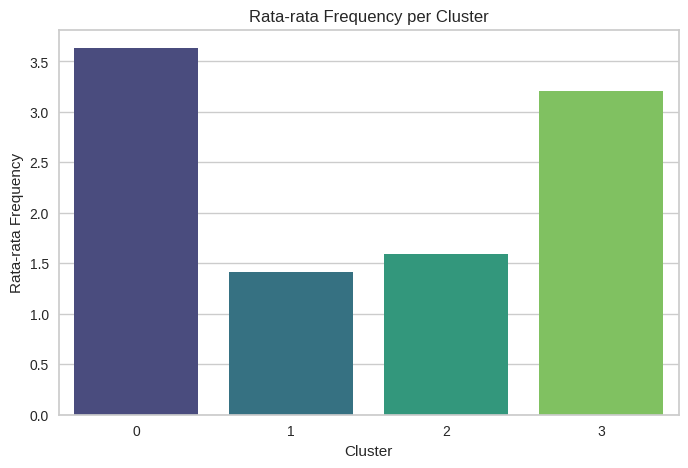

In [ ]:
plt.figure(figsize=(8,5))

freq_mean = df_rfm.groupby('Cluster')['Frequency'].mean()

sns.barplot(
    x=freq_mean.index,
    y=freq_mean.values,
    palette='viridis'
)

plt.title("Rata-rata Frequency per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Rata-rata Frequency")
plt.show()


/tmp/ipykernel_4474/3860575420.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


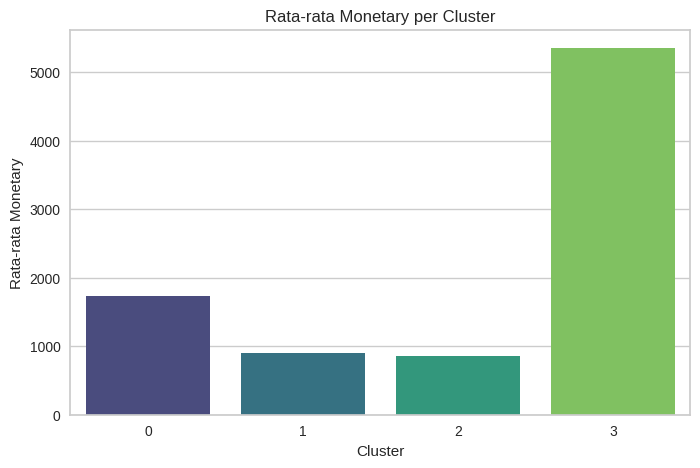

In [ ]:
plt.figure(figsize=(8,5))

monetary_mean = df_rfm.groupby('Cluster')['Monetary'].mean()

sns.barplot(
    x=monetary_mean.index,
    y=monetary_mean.values,
    palette='viridis'
)

plt.title("Rata-rata Monetary per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Rata-rata Monetary")
plt.show()


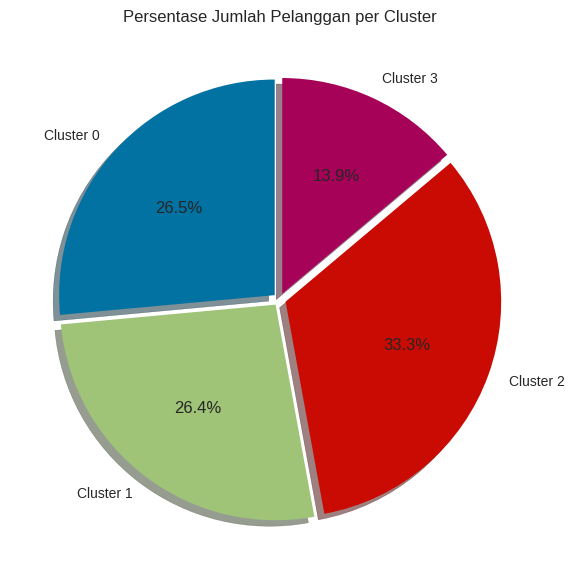

In [ ]:
cluster_counts = df_rfm['Cluster'].value_counts().sort_index()

plt.figure(figsize=(7,7))
plt.pie(
    cluster_counts,
    labels=[f"Cluster {i}" for i in cluster_counts.index],
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.03]*len(cluster_counts),
    shadow=True
)

plt.title("Persentase Jumlah Pelanggan per Cluster")
plt.show()


##8. Churn Rate

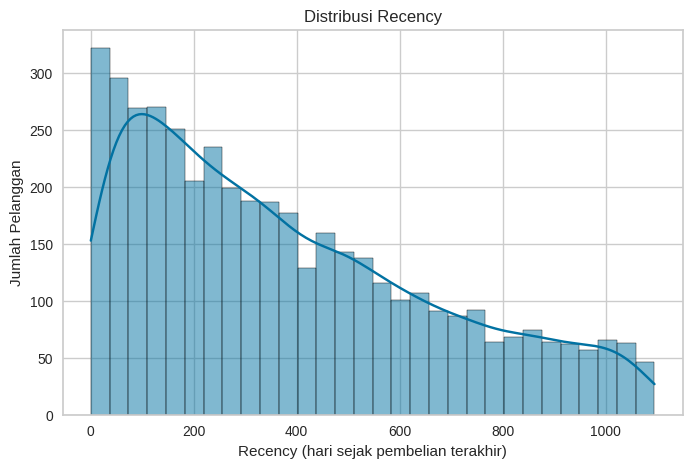

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df_rfm['Recency'], bins=30, kde=True)
plt.title("Distribusi Recency")
plt.xlabel("Recency (hari sejak pembelian terakhir)")
plt.ylabel("Jumlah Pelanggan")
plt.show()


In [ ]:
df_rfm['Recency'].describe()


,Recency
count,4327.000000
mean,379.260689
std,289.956508
min,0.000000
25%,136.500000
50%,311.000000
75%,575.000000
max,1095.000000


In [ ]:
cutoff = 180
df_rfm['is_churn'] = df_rfm['Recency'] > cutoff

churn_rate = df_rfm['is_churn'].mean() * 100

print("Churn Rate:", round(churn_rate, 2),"%")
df_rfm

Churn Rate: 67.74 %


,customer_id,Recency,Frequency,Monetary,Cluster,is_churn
0,CUST1000,237,5,6336,3,True
1,CUST1001,138,2,690,2,False
2,CUST1002,1019,1,999,1,True
3,CUST1003,603,2,444,1,True
4,CUST1004,222,1,796,2,True
...,...,...,...,...,...,...
4322,CUST5993,694,1,796,1,True
4323,CUST5994,583,3,2342,0,True
4324,CUST5997,35,1,798,2,False
4325,CUST5998,83,4,1653,0,False


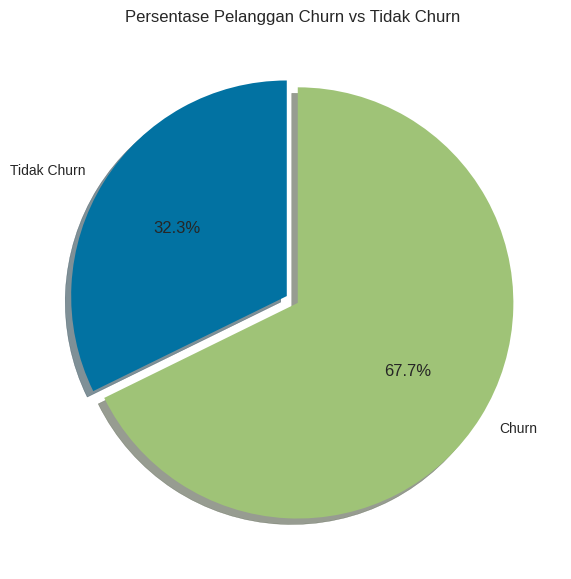

In [ ]:
churn_counts = df_rfm['is_churn'].value_counts().sort_index()

labels = ["Tidak Churn", "Churn"]

plt.figure(figsize=(7,7))
plt.pie(
    churn_counts,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.03, 0.03],
    shadow=True
)

plt.title("Persentase Pelanggan Churn vs Tidak Churn")
plt.show()

In [ ]:
total_customers = len(df_rfm)
total_churn = df_rfm['is_churn'].sum()
total_not_churn = total_customers - total_churn

print("Total pelanggan:", total_customers)
print("Total churn:", total_churn)
print("Total tidak churn:", total_not_churn)

churn_rate = (total_churn / total_customers) * 100
print("\nChurn Rate:", round(churn_rate, 2), "%")

churn_by_cluster = df_rfm.groupby('Cluster')['is_churn'].mean() * 100
print("\nChurn Rate per Cluster (%):")
print(churn_by_cluster.round(2))

summary = pd.DataFrame({
    'Total Customers': [total_customers],
    'Total Churn': [total_churn],
    'Total Not Churn': [total_not_churn],
    'Churn Rate (%)': [round(churn_rate, 2)]
})

print("\nSummary Table:")
display(summary)

Total pelanggan: 4327
Total churn: 2931
Total tidak churn: 1396

Churn Rate: 67.74 %

Churn Rate per Cluster (%):
Cluster
0     49.43
1    100.00
2     61.29
3     56.67
Name: is_churn, dtype: float64

Summary Table:


,Total Customers,Total Churn,Total Not Churn,Churn Rate (%)
0,4327,2931,1396,67.74


##9. CLV (Customer Lifetime Value)

In [ ]:
df_rfm['lifetime'] = 1 / (1 + df_rfm['Recency'])

df_rfm['CLV'] = df_rfm['Frequency'] * df_rfm['Monetary'] * df_rfm['lifetime']
df_rfm[['Recency','Frequency','Monetary','lifetime','CLV']]

,Recency,Frequency,Monetary,lifetime,CLV
0,237,5,6336,0.004202,133.109244
1,138,2,690,0.007194,9.928058
2,1019,1,999,0.000980,0.979412
3,603,2,444,0.001656,1.470199
4,222,1,796,0.004484,3.569507
...,...,...,...,...,...
4322,694,1,796,0.001439,1.145324
4323,583,3,2342,0.001712,12.030822
4324,35,1,798,0.027778,22.166667
4325,83,4,1653,0.011905,78.714286


In [ ]:
tabel_clv_cluster = df_rfm.groupby('Cluster')[['Recency','Frequency','Monetary','CLV']].mean().reset_index()
tabel_clv_cluster

,Cluster,Recency,Frequency,Monetary,CLV
0,0,216.545852,3.632314,1730.659389,150.387379
1,1,774.368329,1.418198,894.573928,1.937900
2,2,240.537179,1.593468,859.829743,24.407369
3,3,269.800000,3.211667,5348.941667,359.221567


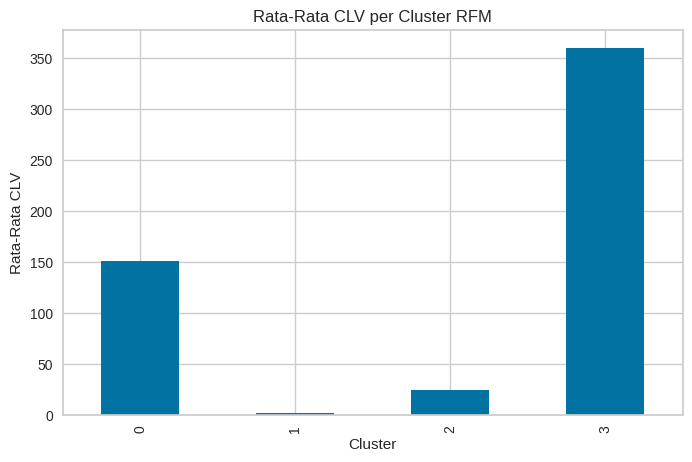

In [ ]:
plt.figure(figsize=(8,5))
df_rfm.groupby('Cluster')['CLV'].mean().plot(kind='bar')
plt.xlabel("Cluster")
plt.ylabel("Rata-Rata CLV")
plt.title("Rata-Rata CLV per Cluster RFM")
plt.show()

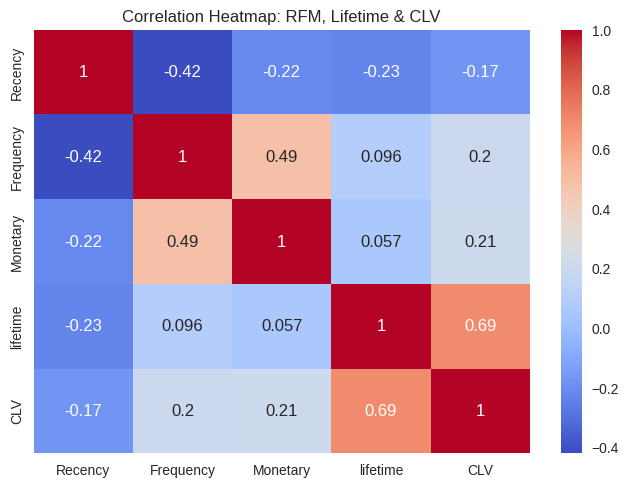

In [ ]:
sns.heatmap(df_rfm[['Recency','Frequency','Monetary','lifetime','CLV']].corr(),
            annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap: RFM, Lifetime & CLV")
plt.show()

In [ ]:
df['Month'] = df['order_date'].dt.to_period('M').astype(str)
df_merge = df.merge(df_rfm[['customer_id', 'Cluster', 'CLV']], on='customer_id', how='left')
clv_perbulan_cluster = df_merge.groupby(['Month', 'Cluster'])['CLV'].mean().reset_index()
pivot_clv = clv_perbulan_cluster.pivot(index='Month', columns='Cluster', values='CLV')
pivot_clv

Cluster,0,1,2,3
Month,,,,
2022-08,97.270427,2.497050,41.804373,103.854802
2022-09,102.477878,2.046891,16.783767,801.798123
2022-10,106.682446,2.352400,28.495668,224.570979
2022-11,153.160638,2.356185,15.945363,235.206833
2022-12,198.597895,2.275078,13.114484,298.887672
2023-01,280.339424,2.049786,24.553330,158.400636
2023-02,123.260303,2.171140,13.869548,748.850838
2023-03,138.619613,2.281257,14.544899,345.355667
2023-04,178.102775,2.820501,13.615993,672.879037


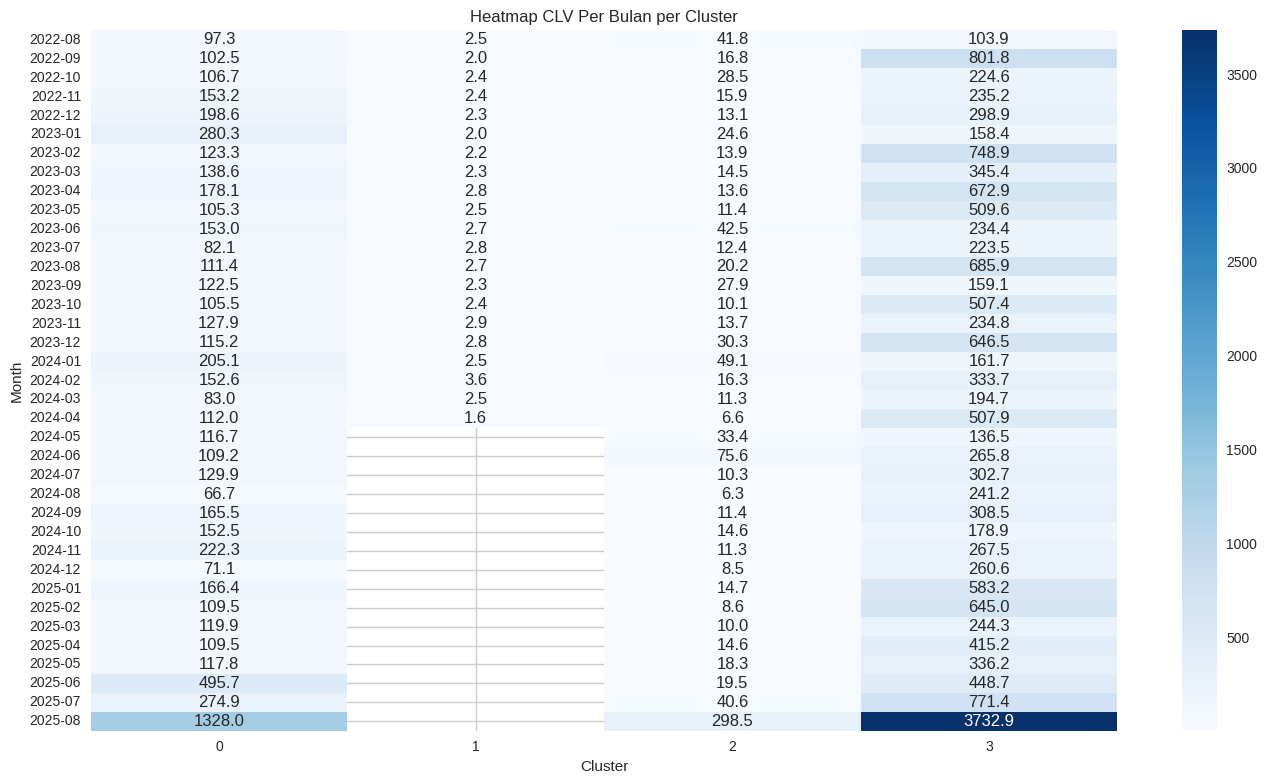

In [ ]:
plt.figure(figsize=(14,8))
sns.heatmap(pivot_clv, annot=True, fmt=".1f", cmap="Blues")
plt.title("Heatmap CLV Per Bulan per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

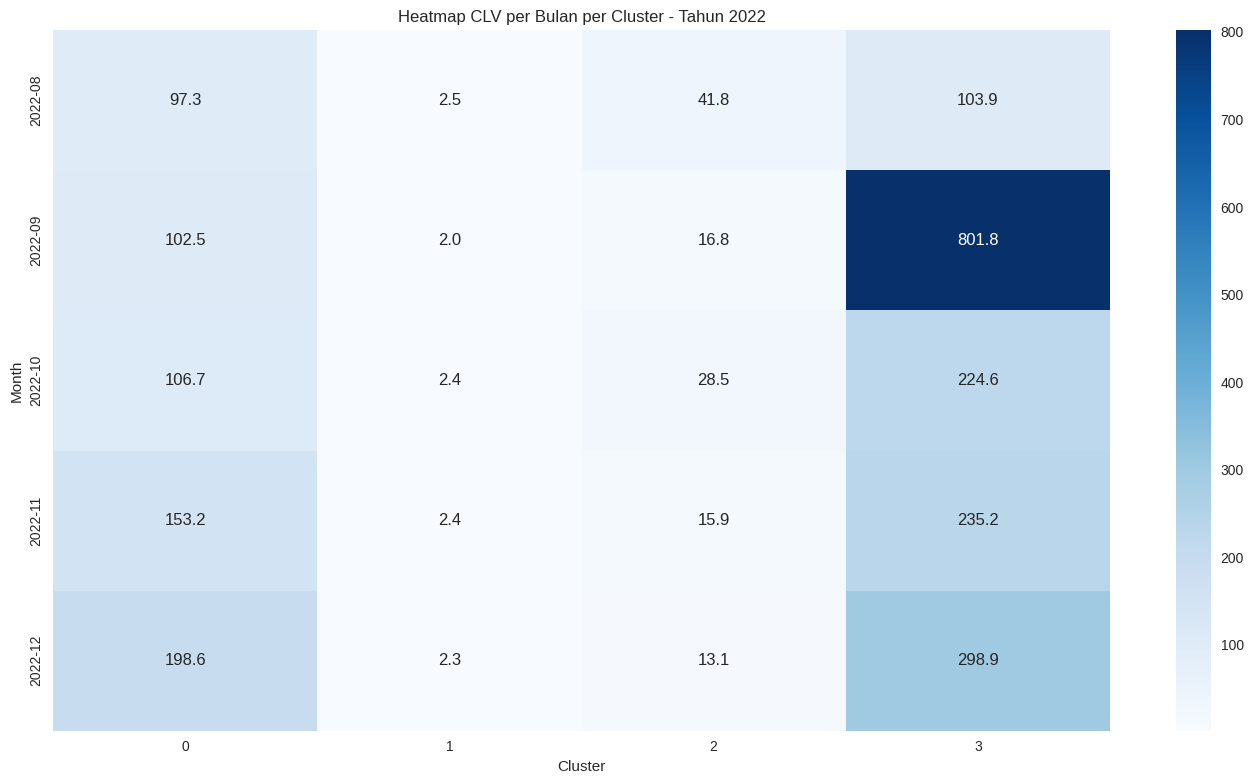

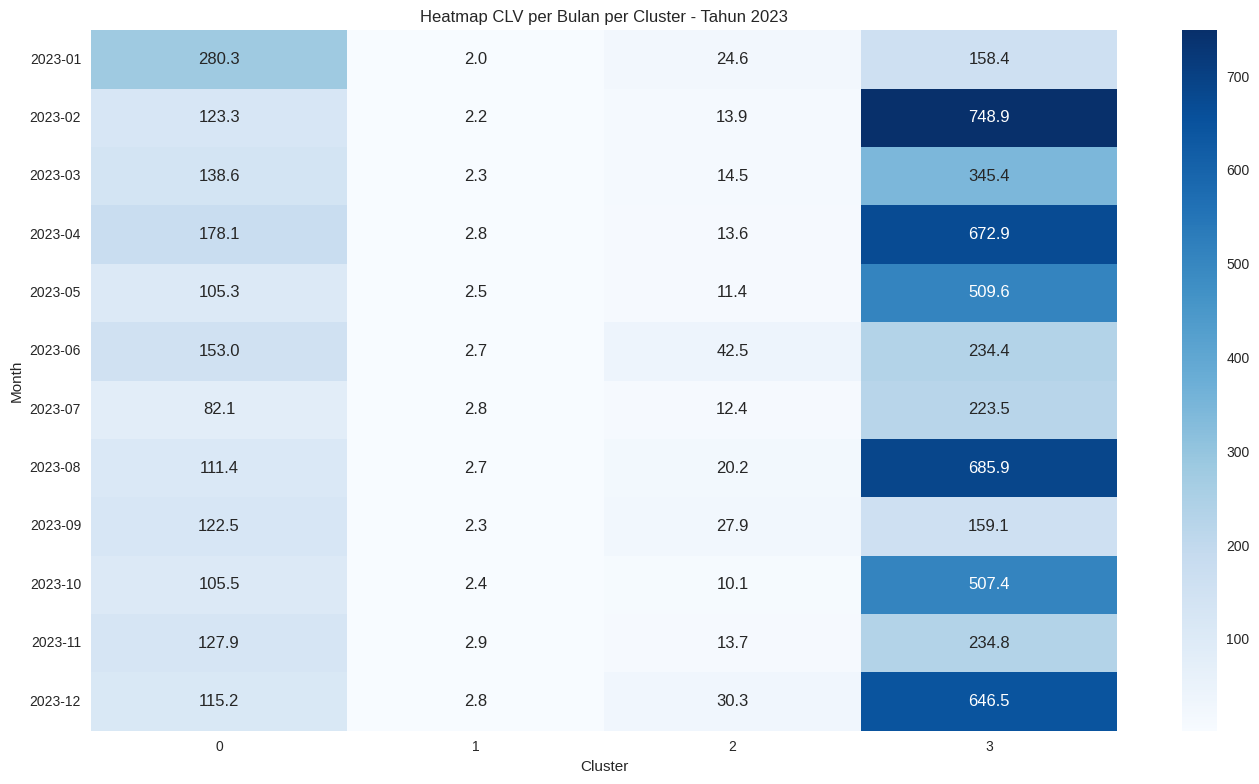

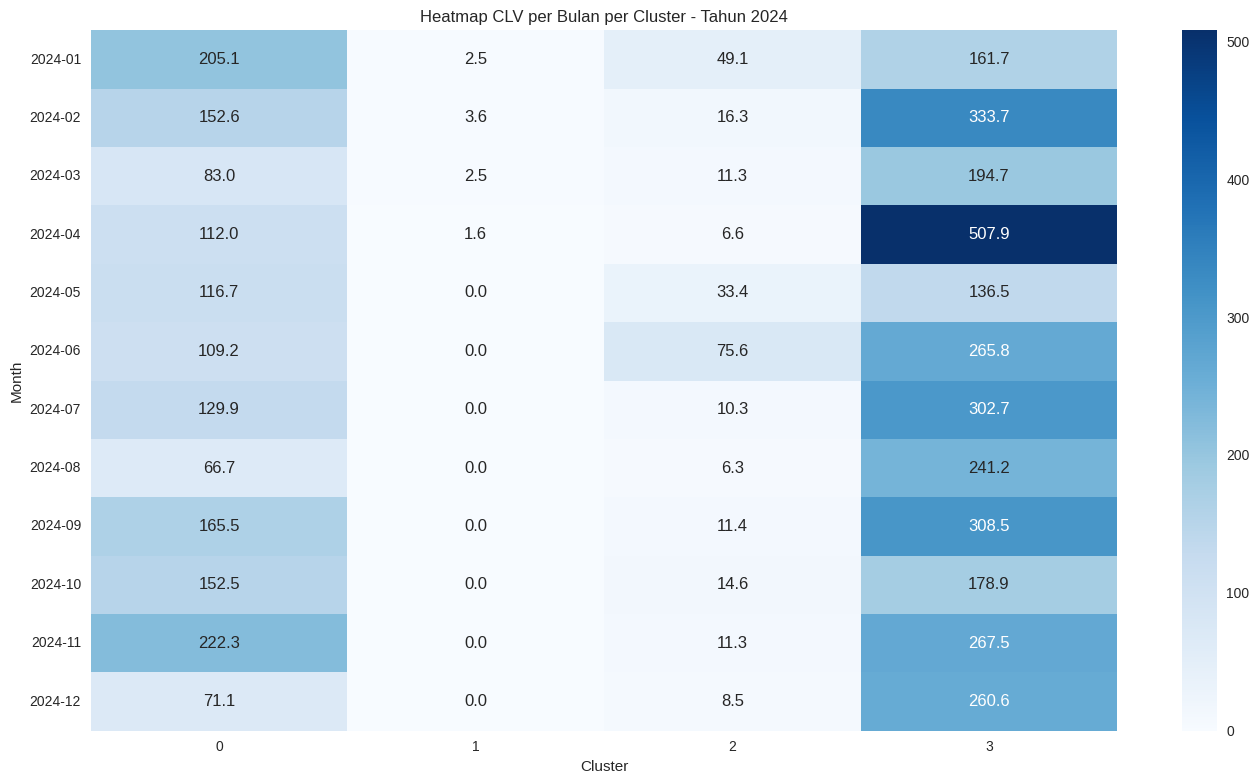

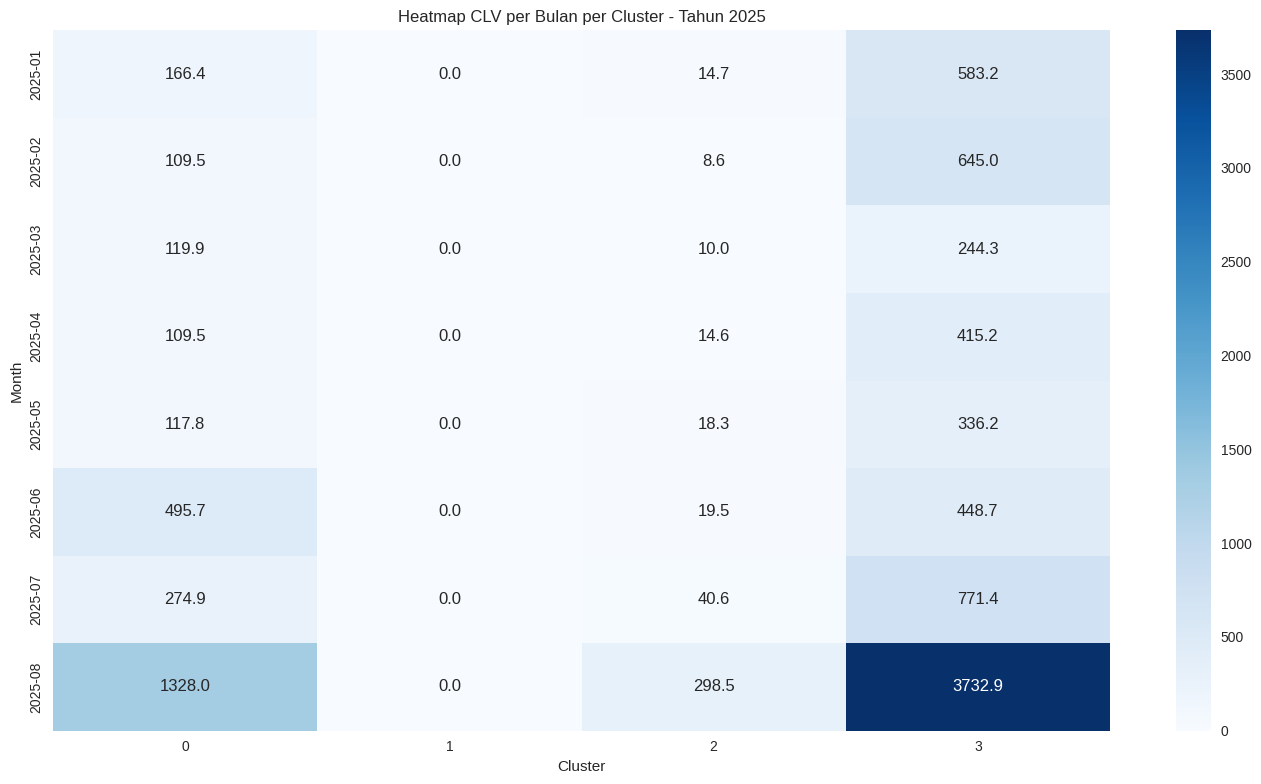

In [ ]:
df_merge['Year'] = pd.to_datetime(df_merge['Month']).dt.year

clv_perbulan_cluster = df_merge.groupby(['Year', 'Month', 'Cluster'])['CLV'].mean().reset_index()

unique_years = clv_perbulan_cluster['Year'].unique()

for year in unique_years:
    data_year = clv_perbulan_cluster[clv_perbulan_cluster['Year'] == year]
    pivot_year = data_year.pivot(index='Month', columns='Cluster', values='CLV')
    pivot_year = pivot_year.reindex(columns=[0, 1, 2, 3])
    pivot_year = pivot_year.fillna(0)
    plt.figure(figsize=(14, 8))
    sns.heatmap(
        pivot_year,
        annot=True,
        fmt=".1f",
        cmap="Blues"
    )
    plt.title(f"Heatmap CLV per Bulan per Cluster - Tahun {year}")
    plt.xlabel("Cluster")
    plt.ylabel("Month")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
